# Assignment 1: Data Profiling (EDA) Report

**Course:** Principles of Data Science  
**Assignment:** Assignment 1 – Data Profiling (10 marks)  
**Student:** LOU XUKUN  
**Matric number:** A207393  
**Dataset:** `V03.csv`  
**Scenario:** Insurance Claims Data Quality and Fraud Risk Profiling

## 1. Scenario

This report profiles an insurance-claims dataset to determine whether it is sufficiently reliable for claim-quality assessment and preliminary fraud-related analysis. Insurance records can contain incomplete policyholder information, unusual claim amounts, inconsistent field formats and imbalanced fraud labels. The analysis therefore checks missingness, outliers, duplicates, invalid values, privacy risks and possible bias.

## 2. Data source and how to obtain it

**Source:** `V03.csv`, provided directly by the lecturer as coursework data.  
**Acquisition method:** The CSV file was obtained from the course materials supplied by the lecturer and uploaded to the notebook environment for analysis.  
**Public URL:** Not applicable / not supplied. No public download URL, publisher, licence or original collection method was included with the lecturer-provided file. A public URL is therefore not claimed or invented. The original provenance should be confirmed with the lecturer if an external source citation is required.

The dataset contains 463 records and 14 columns. The analysis is adapted to the actual field names in the supplied CSV. The notebook strips trailing whitespace from column labels so that `Insurance Type ` is consistently accessed as `Insurance Type`.

**How to run:** Keep `V03.csv` in the same folder as this notebook. In Google Colab, upload the CSV when prompted by the first code cell. Run all cells from top to bottom. Required packages: `pandas`, `numpy`, `matplotlib` and `seaborn`.



In [ ]:
# Import libraries and load the dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_FILE = Path("V03(2).csv")

# Google Colab upload fallback
if not DATA_FILE.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            DATA_FILE = Path(next(iter(uploaded.keys())))
    except ImportError:
        pass

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "V03(2).csv was not found. Place it in the notebook folder "
        "or upload it when running in Google Colab."
    )

df_raw = pd.read_csv(DATA_FILE)

# Standardise column labels (one source column has trailing whitespace)
df_raw.columns = df_raw.columns.str.strip()

print("Dataset shape:", df_raw.shape)
display(df_raw.head())
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types and non-null counts:")
df_raw.info()


Dataset shape: (463, 14)


,ID,Insurance Type,Income of Policy Holder,Marital Status,Num Claimants,Injury Type,Overnight Hospital Stay,Claim Amount,Total Claimed,Num Claims,Num Soft Tissue,% Soft Tissue,Claim Amount Received,Fraud Flag
0,1,CI,0,NaN,2.0,Soft Tissue,No,1581,3274,2,2.0,1.0,0,1
1,2,CI,0,NaN,NaN,Back,Yes,14696,61427,1,0.0,0.0,14696,0
2,3,CI,53318,Married,1.0,Broken Limb,No,-99999,0,0,0.0,0.0,572,0
3,4,CI,0,NaN,3.0,Serious,Yes,273606,0,0,0.0,0.0,273606,0
4,5,CI,0,NaN,4.0,Soft Tissue,No,8916,0,0,0.0,0.0,0,1



Column names:
['ID', 'Insurance Type', 'Income of Policy Holder', 'Marital Status', 'Num Claimants', 'Injury Type', 'Overnight Hospital Stay', 'Claim Amount', 'Total Claimed', 'Num Claims', 'Num Soft Tissue', '% Soft Tissue', 'Claim Amount Received', 'Fraud Flag']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       463 non-null    int64  
 1   Insurance Type           463 non-null    object 
 2   Income of Policy Holder  463 non-null    int64  
 3   Marital Status           156 non-null    object 
 4   Num Claimants            443 non-null    float64
 5   Injury Type              463 non-null    object 
 6   Overnight Hospital Stay  463 non-null    object 
 7   Claim Amount             463 non-null    int64  
 8   Total Claimed            463 non-null    int64  
 9

## 3. Data profiling and issue handling

### 3.1 Initial structure and missing values

The supplied dataset has **463 rows and 14 columns**. The observed profile identifies substantial missingness in `Marital Status` (307 records; 66.31%), as well as missing values in `Num Claimants` (20; 4.32%) and `Num Soft Tissue` (9; 1.94%). The missingness heatmap and summary below are generated from the CSV at runtime.

**Handling decisions:**
- `Marital Status`: retain missing values as missing and create an explicit `Marital Status Missing` indicator. Do not fill the field with the mode because 66.31% is missing and mode imputation could create a misleading majority category.
- `Num Claimants` and `Num Soft Tissue`: preserve the original columns and create median-imputed analysis columns plus missingness indicators. Median imputation is a pragmatic option for numeric counts, but the original values must remain available and imputation must be documented.
- Do not remove complete rows just because one optional field is missing; doing so would discard substantial information.


,Missing Count,Missing Percentage,Data Type
Marital Status,307,66.31,object
Num Claimants,20,4.32,float64
Num Soft Tissue,9,1.94,float64
Insurance Type,0,0.00,object
Income of Policy Holder,0,0.00,int64
ID,0,0.00,int64
Injury Type,0,0.00,object
Overnight Hospital Stay,0,0.00,object
Total Claimed,0,0.00,int64
Claim Amount,0,0.00,int64


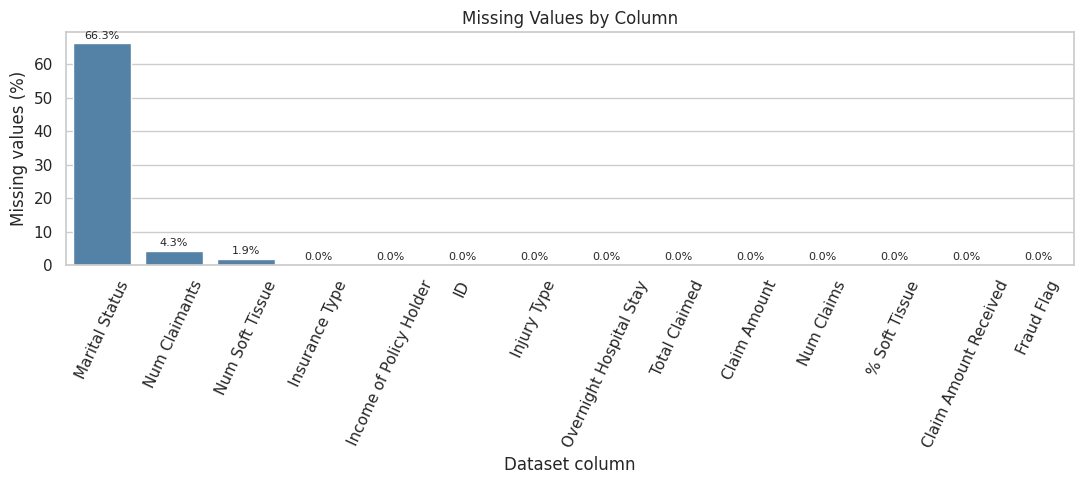

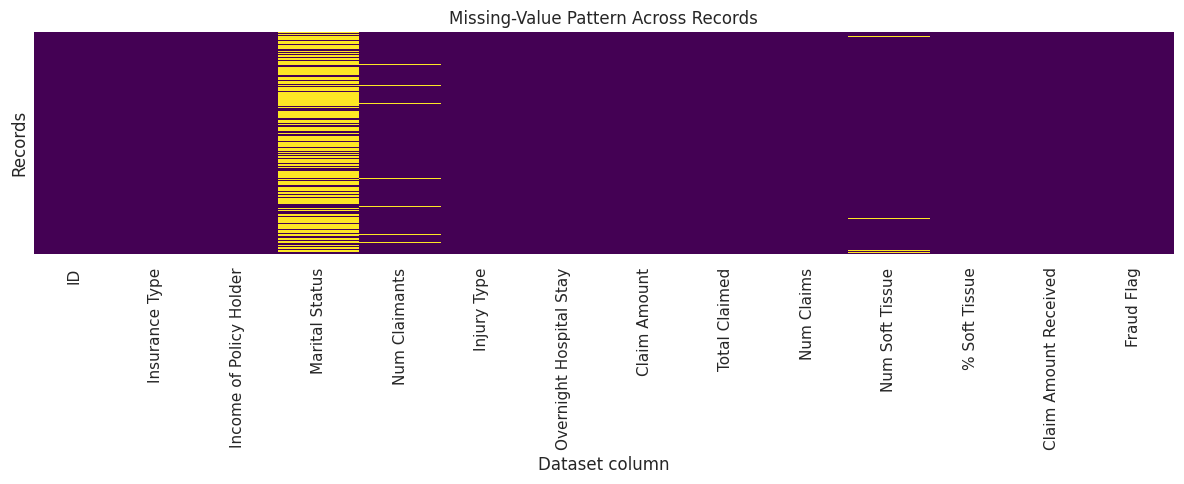

In [ ]:
# Missing-value summary
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing Percentage": (df_raw.isna().mean() * 100).round(2),
    "Data Type": df_raw.dtypes.astype(str)
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary)

# Diagnostic chart 1: missingness by column
missing_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(11, 5))
ax = sns.barplot(x=missing_pct.index, y=missing_pct.values, color="steelblue")
ax.set_title("Missing Values by Column")
ax.set_xlabel("Dataset column")
ax.set_ylabel("Missing values (%)")
ax.tick_params(axis="x", rotation=65)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

# Diagnostic chart 2: missing-value pattern (sample rows if needed)
plt.figure(figsize=(12, 5))
sns.heatmap(df_raw.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing-Value Pattern Across Records")
plt.xlabel("Dataset column")
plt.ylabel("Records")
plt.tight_layout()
plt.show()


### 3.2 Duplicate records and identifier checks

The duplicate checks below calculate the exact number of duplicate rows and duplicate IDs directly from the supplied CSV. `ID` is an identifier, not a predictive measurement; it should be retained for traceability but excluded from statistical outlier detection and later model features.


In [ ]:
# Duplicate checks
exact_duplicate_count = int(df_raw.duplicated().sum())
duplicate_id_count = int(df_raw["ID"].duplicated().sum()) if "ID" in df_raw.columns else None

print("Exact duplicate rows:", exact_duplicate_count)
print("Duplicate IDs:", duplicate_id_count)

# Check whether ID is unique and whether the column has missing values
if "ID" in df_raw.columns:
    print("Missing IDs:", int(df_raw["ID"].isna().sum()))
    print("Unique IDs:", int(df_raw["ID"].nunique(dropna=True)))


Exact duplicate rows: 0
Duplicate IDs: 0
Missing IDs: 0
Unique IDs: 463


### 3.3 Outlier detection using the IQR method

For each numerical field, the interquartile range is calculated as `IQR = Q3 − Q1`. Values below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR` are flagged for investigation. This method identifies statistical extremes; it does **not** prove that a record is wrong.

The IQR summary below calculates the number and percentage of statistical outliers for each numerical field. The results should be checked against domain definitions and source records. Do not automatically delete valid high-value insurance claims.

A separate domain check identified one `Claim Amount` value of **−99999**, which is likely a sentinel/error code rather than a genuine negative claim. The record is flagged and its claim amount is set to missing in the cleaned analytical copy; the original raw data is preserved.


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
2,Claim Amount,3425.5,12615.5,9190.0,-10359.50,26400.50,85,18.36
5,Num Soft Tissue,0.0,0.0,0.0,0.00,0.00,75,16.52
6,% Soft Tissue,0.0,0.0,0.0,0.00,0.00,75,16.20
7,Claim Amount Received,0.0,8293.5,8293.5,-12440.25,20733.75,71,15.33
4,Num Claims,0.0,1.0,1.0,-1.50,2.50,38,8.21
3,Total Claimed,0.0,11676.5,11676.5,-17514.75,29191.25,32,6.91
0,Income of Policy Holder,0.0,33751.5,33751.5,-50627.25,84378.75,0,0.00
1,Num Claimants,1.0,3.0,2.0,-2.00,6.00,0,0.00


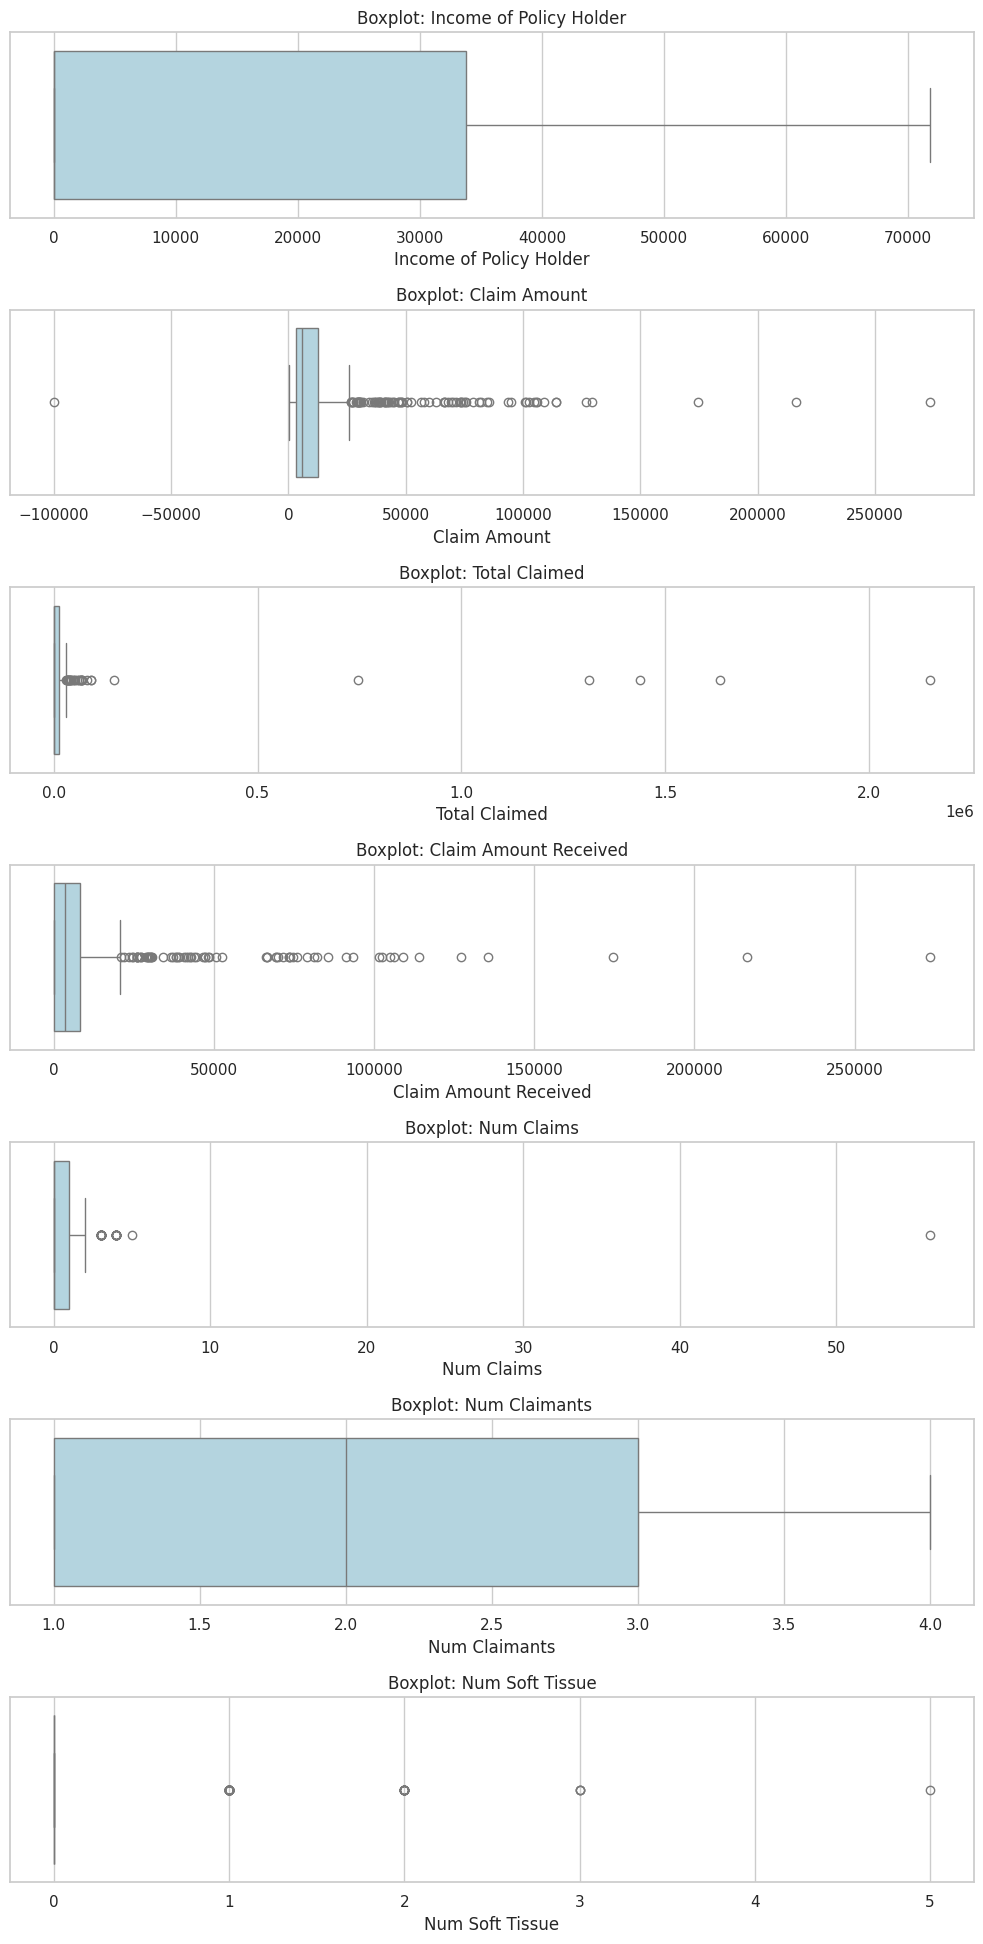

In [ ]:
# IQR outlier summary; exclude identifier and binary target
numeric_cols = df_raw.select_dtypes(include=np.number).columns.tolist()
exclude_cols = {"ID", "Fraud Flag"}
outlier_rows = []

for col in numeric_cols:
    if col in exclude_cols:
        continue
    s = pd.to_numeric(df_raw[col], errors="coerce").dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count,
        "Outlier Percentage": round(count / len(s) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "Outlier Percentage", ascending=False
)
display(outlier_summary)

# Diagnostic chart 3: boxplots for monetary/count variables
box_cols = [
    c for c in ["Income of Policy Holder", "Claim Amount",
                "Total Claimed", "Claim Amount Received",
                "Num Claims", "Num Claimants", "Num Soft Tissue"]
    if c in df_raw.columns
]
fig, axes = plt.subplots(len(box_cols), 1, figsize=(10, 2.8 * len(box_cols)))
if len(box_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, box_cols):
    sns.boxplot(x=df_raw[col], ax=ax, color="lightblue")
    ax.set_title(f"Boxplot: {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()


### 3.4 Other quality issues: invalid values, formats and categories

The audit of the supplied file found:
- One negative `Claim Amount`, equal to −99999. Treat it as a suspected sentinel value, not a genuine negative claim, unless the data dictionary proves otherwise.
- Eleven `% Soft Tissue` values outside the interval [0, 1]. This may indicate that the field is encoded as a percentage from 0 to 100 rather than a fraction. Do not rescale automatically until the variable definition is confirmed.
- `Insurance Type` has only one category (`CI`) in all 463 records. This is not necessarily an invalid value, but it prevents comparisons across insurance types.
- `Fraud Flag` contains only 0 and 1, which is consistent with a binary label.
- Column names are stripped of leading/trailing whitespace during loading.

The code below checks these conditions and displays category counts. Any unexpected category spelling or whitespace should be reviewed before recoding.


In [ ]:
# Domain/range checks
domain_checks = {}

if "Claim Amount" in df_raw:
    domain_checks["Negative Claim Amount rows"] = int((df_raw["Claim Amount"] < 0).sum())
    domain_checks["Claim Amount == -99999 rows"] = int((df_raw["Claim Amount"] == -99999).sum())

for col in ["Total Claimed", "Claim Amount Received", "Income of Policy Holder"]:
    if col in df_raw:
        domain_checks[f"Negative {col} rows"] = int((df_raw[col] < 0).sum())

if "% Soft Tissue" in df_raw:
    domain_checks["% Soft Tissue outside [0,1] rows"] = int(
        ((df_raw["% Soft Tissue"] < 0) | (df_raw["% Soft Tissue"] > 1)).sum()
    )

if "Fraud Flag" in df_raw:
    domain_checks["Fraud Flag values outside {0,1}"] = int(
        (~df_raw["Fraud Flag"].isin([0, 1])).sum()
    )

display(pd.DataFrame.from_dict(domain_checks, orient="index", columns=["Count"]))

# Categorical value counts
categorical_cols = df_raw.select_dtypes(include=["object", "category"]).columns.tolist()
for col in categorical_cols:
    print(f"\n{col} — value counts (including missing):")
    display(df_raw[col].value_counts(dropna=False).rename("Count").to_frame())

# Fraud-label balance
if "Fraud Flag" in df_raw:
    fraud_balance = df_raw["Fraud Flag"].value_counts(dropna=False).sort_index().to_frame("Count")
    fraud_balance["Percentage"] = (
        fraud_balance["Count"] / fraud_balance["Count"].sum() * 100
    ).round(2)
    print("\nFraud Flag distribution:")
    display(fraud_balance)


,Count
Negative Claim Amount rows,1
Claim Amount == -99999 rows,1
Negative Total Claimed rows,0
Negative Claim Amount Received rows,0
Negative Income of Policy Holder rows,0
"% Soft Tissue outside [0,1] rows",11
"Fraud Flag values outside {0,1}",0



Insurance Type — value counts (including missing):


,Count
Insurance Type,
CI,463



Marital Status — value counts (including missing):


,Count
Marital Status,
NaN,307
Married,90
Single,44
Divorced,22


...

,Count
Injury Type,
Broken Limb,166
Soft Tissue,158
Back,106
Serious,33



Overnight Hospital Stay — value counts (including missing):


,Count
Overnight Hospital Stay,
No,328
Yes,135



Fraud Flag distribution:


,Count,Percentage
Fraud Flag,,
0,307,66.31
1,156,33.69


### 3.5 Cleaning strategy and cleaned analytical copy

The cleaning process is conservative and reproducible:
1. Keep `df_raw` unchanged as the original evidence.
2. Standardise column labels by trimming whitespace (already applied during loading).
3. Flag the −99999 `Claim Amount` sentinel and convert only that value to missing in `df_clean`.
4. Create missingness indicator columns for the three incomplete fields.
5. Median-impute the two numeric count fields in separate `_imputed` columns; do not overwrite the raw columns.
6. Leave `Marital Status` missing rather than inventing a category or imputing a majority value.
7. Retain statistical outliers pending source verification. Outlier flags are added for review, not deletion.

This approach avoids irreversible deletion and makes every transformation auditable.


In [ ]:
# Create a separate cleaned copy; never overwrite the raw dataset
df_clean = df_raw.copy()

# Flag and mask the suspected sentinel
if "Claim Amount" in df_clean:
    df_clean["Claim Amount Sentinel Flag"] = (df_clean["Claim Amount"] == -99999).astype(int)
    df_clean.loc[df_clean["Claim Amount"] == -99999, "Claim Amount"] = np.nan

# Missingness indicators and numeric median-imputed companion columns
for col in ["Marital Status", "Num Claimants", "Num Soft Tissue"]:
    if col in df_clean:
        df_clean[f"{col} Missing Flag"] = df_clean[col].isna().astype(int)

for col in ["Num Claimants", "Num Soft Tissue"]:
    if col in df_clean:
        median_value = df_clean[col].median()
        df_clean[f"{col} Imputed"] = df_clean[col].fillna(median_value)

# Add IQR flags for numeric variables (excluding ID and target)
for col in df_clean.select_dtypes(include=np.number).columns:
    if col in {"ID", "Fraud Flag"} or col.endswith("Flag"):
        continue
    s = df_clean[col].dropna()
    if len(s) == 0:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    df_clean[f"{col} IQR Outlier Flag"] = (
        (df_clean[col] < lower) | (df_clean[col] > upper)
    ).fillna(False).astype(int)

print("Raw shape:", df_raw.shape)
print("Clean analytical copy shape:", df_clean.shape)
print("Sentinel values flagged:", int(df_clean.get("Claim Amount Sentinel Flag", pd.Series(dtype=int)).sum()))
display(df_clean.head())


Raw shape: (463, 14)
Clean analytical copy shape: (463, 30)
Sentinel values flagged: 1


,ID,Insurance Type,Income of Policy Holder,Marital Status,Num Claimants,Injury Type,Overnight Hospital Stay,Claim Amount,Total Claimed,Num Claims,Num Soft Tissue,% Soft Tissue,Claim Amount Received,Fraud Flag,Claim Amount Sentinel Flag,Marital Status Missing Flag,Num Claimants Missing Flag,Num Soft Tissue Missing Flag,Num Claimants Imputed,Num Soft Tissue Imputed,Income of Policy Holder IQR Outlier Flag,Num Claimants IQR Outlier Flag,Claim Amount IQR Outlier Flag,Total Claimed IQR Outlier Flag,Num Claims IQR Outlier Flag,Num Soft Tissue IQR Outlier Flag,% Soft Tissue IQR Outlier Flag,Claim Amount Received IQR Outlier Flag,Num Claimants Imputed IQR Outlier Flag,Num Soft Tissue Imputed IQR Outlier Flag
0,1,CI,0,NaN,2.0,Soft Tissue,No,1581.0,3274,2,2.0,1.0,0,1,0,1,0,0,2.0,2.0,0,0,0,0,0,1,1,0,0,1
1,2,CI,0,NaN,NaN,Back,Yes,14696.0,61427,1,0.0,0.0,14696,0,0,1,1,0,2.0,0.0,0,0,0,1,0,0,0,0,0,0
2,3,CI,53318,Married,1.0,Broken Limb,No,NaN,0,0,0.0,0.0,572,0,1,0,0,0,1.0,0.0,0,0,0,0,0,0,0,0,0,0
3,4,CI,0,NaN,3.0,Serious,Yes,273606.0,0,0,0.0,0.0,273606,0,0,1,0,0,3.0,0.0,0,0,1,0,0,0,0,1,0,0
4,5,CI,0,NaN,4.0,Soft Tissue,No,8916.0,0,0,0.0,0.0,0,1,0,1,0,0,4.0,0.0,0,0,0,0,0,0,0,0,0,0


## 4. Diagnostic charts and findings

The charts above are diagnostic rather than presentation-oriented:
- The missingness bar chart and heatmap show where incomplete records occur.
- Boxplots show distributions and potential extreme values requiring investigation.
- Category counts expose the single-category `Insurance Type` field and the available injury/hospital-stay groups.
- The fraud-label count table reveals a class distribution of 307 non-fraud records (66.31%) and 156 fraud records (33.69%) in the supplied file.

These charts help identify data-quality limitations. They should not be interpreted as proof of fraud or as causal findings.


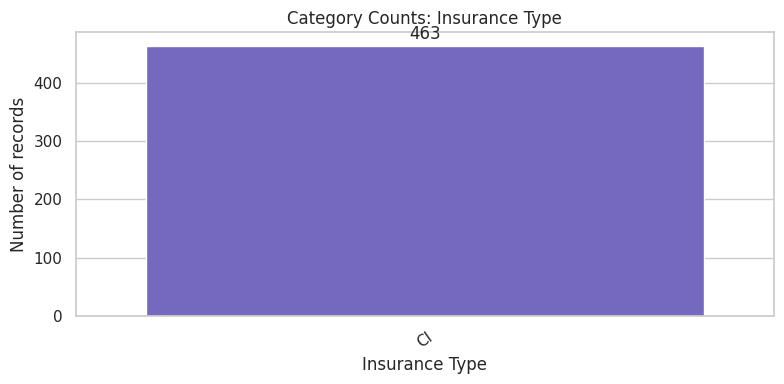

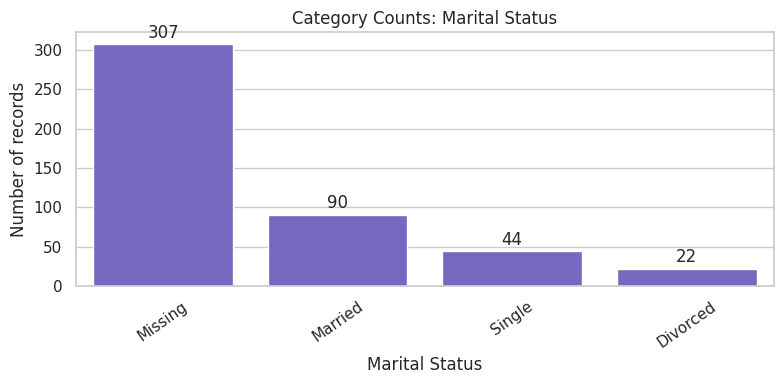

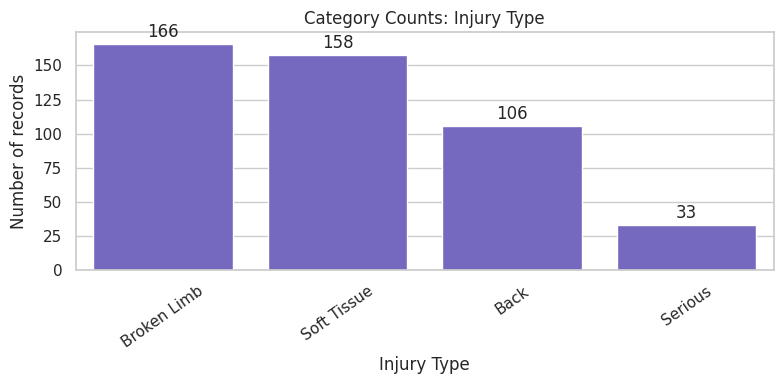

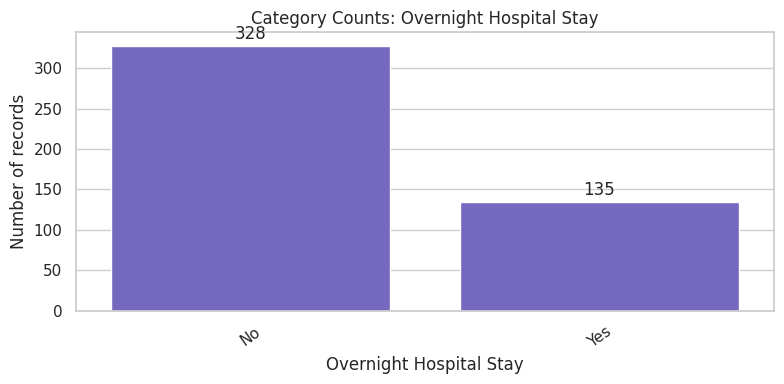

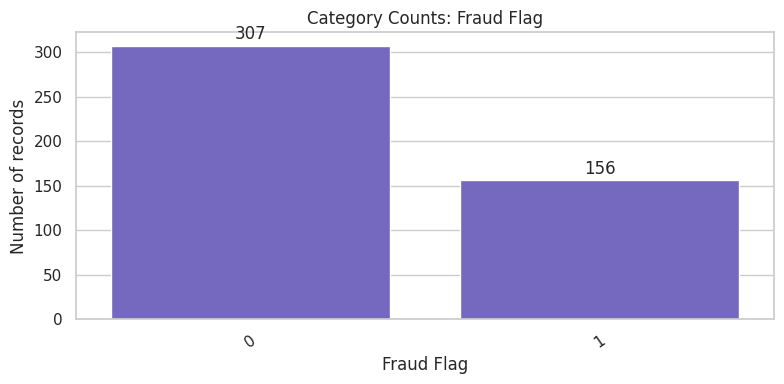

In [ ]:
# Diagnostic chart 4: categorical distributions
cat_plot_cols = [
    c for c in ["Insurance Type", "Marital Status", "Injury Type",
                "Overnight Hospital Stay", "Fraud Flag"]
    if c in df_raw.columns
]
for col in cat_plot_cols:
    counts = df_raw[col].fillna("Missing").astype(str).value_counts()
    plt.figure(figsize=(8, 4))
    ax = sns.barplot(x=counts.index, y=counts.values, color="slateblue")
    ax.set_title(f"Category Counts: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of records")
    ax.tick_params(axis="x", rotation=35)
    for container in ax.containers:
        ax.bar_label(container, padding=2)
    plt.tight_layout()
    plt.show()


## 5. PII and bias risks

### Personally identifiable and sensitive information
The dataset contains an `ID` field and insurance-related attributes such as policyholder income, claim amounts, injury type, marital status and fraud labels. Although a sequential ID may not directly identify a person on its own, it can become identifying when linked with external records. Income, marital status, injury details and fraud labels are sensitive in context.

**Mitigation:** remove or pseudonymise direct identifiers before sharing; restrict access to row-level data; avoid publishing individual records; minimise fields used for analysis; and follow the dataset licence and institutional privacy rules. Do not attempt to re-identify policyholders.

### Sampling and representation bias
The file contains only one `Insurance Type` category, so it cannot represent or compare other insurance types. The fraud label is imbalanced: 66.31% class 0 and 33.69% class 1. The marital-status field is missing for 66.31% of records, which may create bias if missingness is related to a group or collection process. The dataset's collection period, geographic coverage and sampling method are not documented in the supplied file, so representativeness cannot be established.
.


## 6. Conclusion

The dataset is **partially fit** for a data-profiling exercise and cautious exploratory analysis of the available insurance-claim fields. It contains useful examples of data-quality problems: substantial missingness in `Marital Status`, missing numeric count fields, a suspicious −99999 claim amount, IQR-flagged extreme values, uncertainty about the scale of `% Soft Tissue`, a single insurance-type category and an imbalanced fraud label.

The dataset is **not yet suitable for unqualified fraud modelling or broad population conclusions**. The lecturer-provided file does not include a public source URL, licence, collection method, time period or data dictionary. In particular, the meaning of `% Soft Tissue` and the −99999 sentinel must be confirmed with the data owner. The cleaning copy preserves raw values and flags issues rather than silently deleting records. After source clarification and validation, the dataset may be reconsidered for a narrowly defined analysis.

